# Industrial Defect Detection using Robust Distribution Alignment and Continual Adaptation with few-shot learning and new defect classification

## Robust Distribution Alignment Implementation

### Import torch and cuda

In [1]:
import torch
torch.cuda.is_available()

True

In [2]:
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA build: 13.0
CUDA available: True
GPU count: 1
GPU: NVIDIA GeForce RTX 2060 with Max-Q Design


### Imports

In [3]:
from dataclasses import dataclass
import pandas as pd
import torch
from typing import Tuple
import torchvision.transforms as T
import torchvision.transforms.functional as F
import os,glob, random
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from imagecorruptions import corrupt
import torch.nn as nn
import torch.nn.functional as Fn
from torchvision.models import wide_resnet50_2, Wide_ResNet50_2_Weights
from sklearn.metrics import roc_auc_score
import time
import matplotlib.pyplot as plt

C:\Users\Niharika.S.Reddy\AppData\Roaming\Python\Python313\site-packages\imagecorruptions\corruptions.py:17: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


### Configuration

### These values or parameters are mentioned in paper - Robust distribution alignment (liao.et.al)
- adaptation_ratio = 20%
- Corruptions: gaussian noise, defocus blur, brightness, contrast, at severity 5
- memory_bank: size N x M
- Updated params: BatchNorm affine only
- Target augmentation
- ReallAD input size = 1024


### These values are outside and will be tunable
- WideResNet50 and layer2/layer3 features (from the PatchCore paper)
- 256 resize and 224 crop
- ImageNet mean/std
- Core-set ratio (e.g., 1-10%)
- Learning rate, epochs, batch size
- Sinkhorn ε and number of iterations
= num_workers and seed

In [4]:
@dataclass
class Configuration:

    image_size: int = 256
    batch_size_source: int = 16
    resize_size: int = 256
    crop_size: int = 224
    mean: Tuple[float, ...] = (0.485, 0.456, 0.406)
    std: Tuple[float, ...] = (0.229, 0.224, 0.225)
    backbone_name: str = "wide_resnet50_2"
    feature_layers: Tuple[str, ...] = ("layer2","layer3")
    coreset_ratio: float = 0.2
    adaption_ratio: float = 0.20
    adapt_ratio: float = 0.2
    sinkhorn_lr: float = 1e-4
    epochs: int=10
    batch_size: int = 16
    sinkhorn_eps: float = 0.05
    sinkhorn_iters: int = 50
    corruptions: Tuple[str, ...] = ("gaussian_noise", "defocus_blur", "brightness", "contrast")
    severity: int=5
    seed: int=42
    num_workers: int=0
    root: str = "./data"
    category: str = "bottle"
    embed_dim: int = 1024
    max_adapt_patches: int = 1024
    adapt_batch_size: int =8
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    seed: int = 42
    assignment: str="discrete"
    aug_mode: str = "augment"

CFG = Configuration()

from contextlib import contextmanager

@contextmanager
def cfg_override(CFG, **kw):
    old = {k: getattr(CFG, k) for k in kw}
    for k, v in kw.items():
        setattr(CFG, k, v)
    try:
        yield
    finally:
        for k, v in old.items():
            setattr(CFG, k, v)

### Dataset & Image transformation

In [5]:
def convert_to_rgb(image):
    return image.convert("RGB")

def resize(image,image_size):
    return F.resize(image, [image_size,image_size], interpolation=T.InterpolationMode.BILINEAR)

def center_crop(image, image_size):
    return F.center_crop(image, [image_size,image_size])

def convert_to_tensor(image):
    return F.to_tensor(image)

def normalize_with_imagenet(tensor, mean, std):
    return F.normalize(tensor, mean=list(mean), std=list(std))

def base_transform(image, CFG):
    image = convert_to_rgb(image)
    image = resize(image, CFG.resize_size)
    image = center_crop(image, CFG.crop_size)
    tensor = convert_to_tensor(image)
    return normalize_with_imagenet(tensor, CFG.mean, CFG.std)

### Masking ground truth

In [6]:
def mask_transform(mask, CFG):
    mask = F.resize(mask, [CFG.resize_size, CFG.resize_size], interpolation=F.InterpolationMode.NEAREST)
    mask = F.center_crop(mask, [CFG.crop_size, CFG.crop_size])
    mask = F.to_tensor(mask)
    return (mask > 0.5).float()

In [7]:
class SourceDataset(Dataset):
    def __init__(self, CFG, root="./data", category="bottle"):
        self.CFG = CFG
        self.paths = sorted(glob.glob(os.path.join(root, category, "train", "good", "*.*")))

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx])
        return base_transform(img, self.CFG)

In [8]:
def apply_corruption(pil_img, name, severity, seed=None):
    if seed is not None:
        np.random.seed(seed)
    arr = np.array(pil_img.convert("RGB"))
    out = corrupt(arr, corruption_name=name, severity=severity)
    return Image.fromarray(np.uint8(out))


In [9]:
class TestDataset(Dataset):
    def __init__(self, root, category, CFG, corruption=None):
        self.CFG=CFG
        self.corruption=corruption
        test_dir=os.path.join(root, category,"test")
        gt_dir=os.path.join(root, category, "ground_truth")
        self.items=[]
        for defect in sorted(os.listdir(test_dir)):
            for p in sorted(glob.glob(os.path.join(test_dir, defect, "*.*"))):
                if defect == "good":
                    self.items.append((p,0,None))
                else:
                    stem=os.path.splitext(os.path.basename(p))[0]
                    mp=os.path.join(gt_dir, defect, stem+"_mask.png")
                    self.items.append((p,1,mp))
        self.labels = [it[1] for it in self.items]
    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        path, label, mpath = self.items[idx]
        img = Image.open(path).convert("RGB")
        if self.corruption is not None:
            img = apply_corruption(img, self.corruption, self.CFG.severity, seed=self.CFG.seed + idx)
        x=base_transform(img, self.CFG)

        if mpath is not None and os.path.exists(mpath):
            m=mask_transform(Image.open(mpath).convert("L"), self.CFG)

        else:
            m=torch.zeros(1, self.CFG.crop_size, self.CFG.crop_size)
        return x, label, m

In [10]:
def split_target(dataset, CFG):
    idx = np.arange(len(dataset))
    tr_idx, te_idx = train_test_split(
        idx, train_size=CFG.adapt_ratio, stratify=dataset.labels, random_state=CFG.seed
    )
    return Subset(dataset, tr_idx.tolist()), Subset(dataset, te_idx.tolist())

In [11]:
class AdaptDataset(Dataset):
    def __init__(self, subset, augment=True):
        self.subset = subset
        self.augment = augment

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        x, _, _ = self.subset[idx]
        if self.augment:
            k = random.randint(0, 3)
            x = torch.rot90(x, k, dims=(1, 2))
        return x

In [12]:
def build_loaders(root, category, corruption, CFG):
    source_ds = SourceDataset(CFG, root, category)
    target_ds = TestDataset(root, category, CFG, corruption=corruption)
    target_tr, target_te = split_target(target_ds, CFG)

    source_loader = DataLoader(source_ds, batch_size=CFG.batch_size,shuffle=False, num_workers=CFG.num_workers)

    adapt_loader = DataLoader(AdaptDataset(target_tr), batch_size=CFG.batch_size,shuffle=True, num_workers=CFG.num_workers, drop_last=True)

    test_loader = DataLoader(target_te, batch_size=CFG.batch_size, shuffle=False,num_workers=CFG.num_workers)

    return source_loader, adapt_loader, test_loader

### Feature Extraction and Memory Bank

In [13]:
class FeatureExtractor(nn.Module):
    def __init__(self, CFG):
        super().__init__()
        net = wide_resnet50_2(weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.layer1, self.layer2, self.layer3 = net.layer1, net.layer2, net.layer3
        self.embed_dim = CFG.embed_dim
        for p in self.parameters():
            p.requires_grad = False

    def forward(self, x):
        x = self.layer1(self.stem(x))
        f2 = self.layer2(x)
        f3 = self.layer3(f2)
        f2 = Fn.avg_pool2d(f2, 3, 1, 1)
        f3 = Fn.avg_pool2d(f3, 3, 1, 1)
        f3 = Fn.interpolate(f3, size=f2.shape[-2:], mode="bilinear",align_corners=False)
        f = torch.cat([f2, f3], dim=1)

        B, C, H, W = f.shape
        f = f.permute(0, 2, 3, 1).reshape(B * H * W, 1, C)
        f = Fn.adaptive_avg_pool1d(f, self.embed_dim).squeeze(1)
        return f.reshape(B, H * W, self.embed_dim)


@torch.no_grad()
def extract_source_features(model, loader, device):
    model.eval()
    all_feats = []
    for x in loader:
        all_feats.append(model(x.to(device)))
    feats = torch.cat(all_feats, dim=0)
    return feats.reshape(-1, feats.shape[-1])


@torch.no_grad()
def greedy_coreset(features, n_select, proj_dim=128, seed=0):
    device = features.device
    g = torch.Generator(device=device).manual_seed(seed)
    proj = torch.randn(features.shape[1], proj_dim, generator=g, device=device)
    reduced = features @ proj
    N = reduced.shape[0]
    selected = torch.empty(n_select, dtype=torch.long, device=device)
    selected[0] = torch.randint(0, N, (1,), generator=g, device=device)
    min_d = torch.cdist(reduced, reduced[selected[0]].unsqueeze(0)).squeeze(1)

    for i in range(1, n_select):
        nxt = torch.argmax(min_d)
        selected[i] = nxt
        d = torch.cdist(reduced, reduced[nxt].unsqueeze(0)).squeeze(1)
        min_d = torch.minimum(min_d, d)
    return features[selected]


def build_memory_bank(model, source_loader, CFG):
    feats = extract_source_features(model, source_loader, CFG.device)
    n_m = int(CFG.coreset_ratio * feats.shape[0])
    print(f"Source patches: {feats.shape[0]}, memory bank size N_M: {n_m}")
    bank = greedy_coreset(feats, n_m)
    del feats
    torch.cuda.empty_cache()
    return bank


@torch.no_grad()
def score_images(model, loader, memory_bank, device):
    model.eval()
    scores, labels = [], []
    for x, y, _ in loader:
        feats = model(x.to(device))
        for i in range(feats.shape[0]):
            d = torch.cdist(feats[i], memory_bank)
            patch_scores = d.min(dim=1).values
            scores.append(patch_scores.max().item())
        labels.extend(y.tolist())
    return np.array(scores), np.array(labels)


model = FeatureExtractor(CFG).to(CFG.device)
source_ds = SourceDataset(CFG, CFG.root, CFG.category)

source_loader = DataLoader(
    source_ds,
    batch_size=CFG.batch_size,
    shuffle=False,
    num_workers=CFG.num_workers
)

memory_bank = build_memory_bank(
    model,
    source_loader,
    CFG
)

clean_ds = TestDataset(
    CFG.root,
    CFG.category,
    CFG,
    corruption=None
)

clean_loader = DataLoader(
    clean_ds,
    batch_size=CFG.batch_size,
    shuffle=False,
    num_workers=CFG.num_workers
)

s, y = score_images(
    model,
    clean_loader,
    memory_bank,
    CFG.device
)
print("Clean image AUROC:", roc_auc_score(y, s))

Source patches: 163856, memory bank size N_M: 32771
Clean image AUROC: 1.0


### Base evaluation on corrupted data

In [14]:
def make_test_split(corruption, CFG):
    ds = TestDataset(
        CFG.root,
        CFG.category,
        CFG,
        corruption=corruption
    )
    tr, te = split_target(ds, CFG)
    return tr, te

def make_loader(subset, CFG):
    return DataLoader(
        subset,
        batch_size=CFG.batch_size,
        shuffle=False,
        num_workers=CFG.num_workers
    )

def evaluate(model, loader, memory_bank, CFG):
    s, y = score_images(model, loader, memory_bank, CFG.device)
    return roc_auc_score(y, s)

baseline_results = {}

_, clean_te = make_test_split(None, CFG)
baseline_results["clean"] = evaluate(model, make_loader(clean_te, CFG), memory_bank, CFG)
print(f"clean: {baseline_results['clean']:.4f}")


for c in CFG.corruptions:
    _, target_te = make_test_split(c, CFG)
    baseline_results[c] = evaluate(model, make_loader(target_te, CFG), memory_bank, CFG)
    print(f"{c}: {baseline_results[c]:.4f}")


print(pd.Series(baseline_results, name="w/o adapt AUROC").round(4))

clean: 1.0000
gaussian_noise: 0.7953
defocus_blur: 1.0000
brightness: 1.0000
contrast: 0.7132
clean             1.0000
gaussian_noise    0.7953
defocus_blur      1.0000
brightness        1.0000
contrast          0.7132
Name: w/o adapt AUROC, dtype: float64


### Sinkhorn and discretization functions

In [15]:
def cost_matrix(z, bank):
    return torch.cdist(z, bank)

def sample_patches(feats, max_patches):
    z = feats.reshape(-1, feats.shape[-1])
    if z.shape[0] > max_patches:
        idx = torch.randperm(z.shape[0], device=z.device)[:max_patches]
        z = z[idx]
    return z


@torch.no_grad()
def sinkhorn(C, eps, n_iters):
    N, M = C.shape
    Cn = C / C.mean()
    logK = -Cn / eps
    log_a = -torch.log(torch.tensor(float(N), device=C.device))
    log_b = -torch.log(torch.tensor(float(M), device=C.device))
    log_u = torch.zeros(N, device=C.device)
    log_v = torch.zeros(M, device=C.device)
    for _ in range(n_iters):
        log_u = log_a - torch.logsumexp(logK + log_v[None, :], dim=1)
        log_v = log_b - torch.logsumexp(logK + log_u[:, None], dim=0)
    return torch.exp(logK + log_u[:, None] + log_v[None, :])


@torch.no_grad()
def discretize(gamma):
    N, M = gamma.shape
    pi = torch.zeros(N, M, dtype=torch.bool, device=gamma.device)
    pi[torch.arange(N, device=gamma.device), gamma.argmax(dim=1)] = True
    pi[gamma.argmax(dim=0), torch.arange(M, device=gamma.device)] = True
    return pi


def robust_sinkhorn_loss(feats, bank, CFG, return_stats=False):
    z = sample_patches(feats, CFG.max_adapt_patches)
    C = cost_matrix(z, bank)
    gamma = sinkhorn(C.detach(), CFG.sinkhorn_eps, CFG.sinkhorn_iters)
    pi = discretize(gamma)
    loss = C[pi].sum() / z.shape[0]
    if return_stats:
        return loss, gamma, pi
    return loss


tr, _ = make_test_split("gaussian_noise", CFG)
batch = next(iter(DataLoader(AdaptDataset(tr), batch_size=CFG.batch_size, shuffle=True)))


with torch.no_grad():
    feats = model(batch.to(CFG.device))
loss, gamma, pi = robust_sinkhorn_loss(
    feats,
    memory_bank,
    CFG,
    return_stats=True
)

N, M = gamma.shape
print("loss:", loss.item())
print("row sums vs 1/N_tp:", gamma.sum(1).mean().item(), 1 / N)
print("col sums vs 1/N_M :", gamma.sum(0).mean().item(), 1 / M)
print("nonzeros in pi:", pi.sum().item(), "of", N * M)

loss: 56.03764343261719
row sums vs 1/N_tp: 0.0009765629656612873 0.0009765625
col sums vs 1/N_M : 3.0514798709191382e-05 3.0514784413048123e-05
nonzeros in pi: 33290 of 33557504


### Adaptation loop, batchNorm-only updates

In [16]:
def make_adapt_model(CFG):
    m = FeatureExtractor(CFG).to(CFG.device)
    bn_params = []
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            for p in (mod.weight, mod.bias):
                p.requires_grad = True
                bn_params.append(p)
    m.eval()
    return m, bn_params


def adapt(model, bn_params, adapt_subset, memory_bank, CFG):
    loader = DataLoader(
        AdaptDataset(adapt_subset, augment=True),
        batch_size=CFG.adapt_batch_size,
        shuffle=True,
        num_workers=CFG.num_workers
    )

    opt = torch.optim.Adam(bn_params, lr=CFG.sinkhorn_lr)
    history = []

    for epoch in range(CFG.epochs):
        model.eval()
        total, n = 0.0, 0
        for x in loader:
            feats = model(x.to(CFG.device))
            loss = robust_sinkhorn_loss(feats, memory_bank, CFG)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item(); n += 1
        history.append(total / n)
        print(f"  epoch {epoch+1}/{CFG.epochs}  loss {history[-1]:.4f}")
    return history


def run_roda(corruption, memory_bank, CFG):
    torch.manual_seed(CFG.seed); random.seed(CFG.seed); np.random.seed(CFG.seed)
    target_tr, target_te = make_test_split(corruption, CFG)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    auroc = evaluate(model_a, make_loader(target_te, CFG), memory_bank, CFG)
    return auroc, history


auroc, hist = run_roda("gaussian_noise", memory_bank, CFG)
print(f"gaussian_noise  w/o adapt: {baseline_results['gaussian_noise']:.4f}  RoDA: {auroc:.4f}")

  epoch 1/10  loss 55.8129
  epoch 2/10  loss 54.8227
  epoch 3/10  loss 53.5901
  epoch 4/10  loss 53.3086
  epoch 5/10  loss 52.2126
  epoch 6/10  loss 51.2922
  epoch 7/10  loss 50.2338
  epoch 8/10  loss 49.6142
  epoch 9/10  loss 48.8424
  epoch 10/10  loss 47.8908
gaussian_noise  w/o adapt: 0.7953  RoDA: 0.8554


### Run RoDA on all corruptions and compare

[gaussian_noise] seed 0
  epoch 1/10  loss 56.7640
  epoch 2/10  loss 55.2413
  epoch 3/10  loss 53.9406
  epoch 4/10  loss 53.2700
  epoch 5/10  loss 52.1552
  epoch 6/10  loss 51.1663
  epoch 7/10  loss 49.7278
  epoch 8/10  loss 49.2040
  epoch 9/10  loss 49.1136
  epoch 10/10  loss 48.1146
  -> AUROC 0.8542
[gaussian_noise] seed 1
  epoch 1/10  loss 55.9949
  epoch 2/10  loss 54.9071
  epoch 3/10  loss 53.9810
  epoch 4/10  loss 53.0522
  epoch 5/10  loss 52.2386
  epoch 6/10  loss 51.4549
  epoch 7/10  loss 49.9319
  epoch 8/10  loss 49.6985
  epoch 9/10  loss 48.7051
  epoch 10/10  loss 48.4704
  -> AUROC 0.8566
[gaussian_noise] seed 2
  epoch 1/10  loss 55.9320
  epoch 2/10  loss 55.5907
  epoch 3/10  loss 54.7582
  epoch 4/10  loss 53.6039
  epoch 5/10  loss 51.9840
  epoch 6/10  loss 50.6068
  epoch 7/10  loss 49.9989
  epoch 8/10  loss 49.5435
  epoch 9/10  loss 48.9109
  epoch 10/10  loss 48.0084
  -> AUROC 0.8554
[gaussian_noise] done in 59s

[defocus_blur] seed 0
  epoch 1

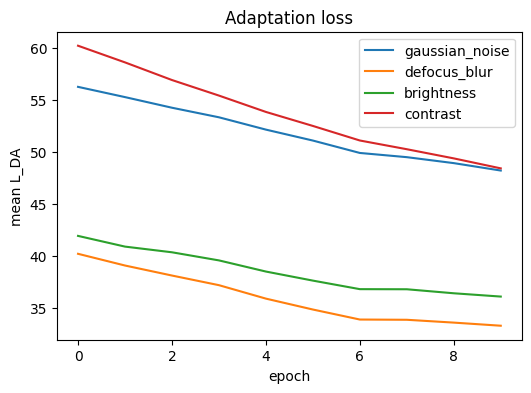

In [17]:
CFG.sinkhorn_lr = 1e-4
CFG.epochs = 10
SEEDS = [0,1,2]

class CachedDataset(Dataset):
    def __init__(self, subset):
        self.items = [subset[i] for i in range(len(subset))]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        return self.items[idx]


def run_roda_seed(target_tr, target_te, memory_bank, CFG, seed):

    torch.manual_seed(seed);
    random.seed(seed);
    np.random.seed(seed)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    auroc = evaluate(model_a, make_loader(target_te, CFG), memory_bank, CFG)

    del model_a, bn_params
    torch.cuda.empty_cache()
    return auroc, history

roda_runs = {}
histories = {}


for c in CFG.corruptions:
    t0 = time.time()
    tr, te = make_test_split(c, CFG)
    tr, te = CachedDataset(tr), CachedDataset(te)
    roda_runs[c], histories[c] = [], []
    for sd in SEEDS:
        print(f"[{c}] seed {sd}")
        a, h = run_roda_seed(tr, te, memory_bank, CFG, sd)
        roda_runs[c].append(a)
        histories[c].append(h)
        print(f"  -> AUROC {a:.4f}")
    print(f"[{c}] done in {time.time()-t0:.0f}s\n")


rows = []
for c in CFG.corruptions:
    m, s = np.mean(roda_runs[c]), np.std(roda_runs[c])
    rows.append({
        "corruption": c,
        "clean": baseline_results["clean"],
        "w/o adapt": baseline_results[c],
        "RoDA mean":m,
        "RoDA std":s,
        "diff":m-baseline_results[c],
    })
results_df = pd.DataFrame(rows).set_index("corruption").round(4)
print(results_df)


plt.figure(figsize=(6,4))
for c in CFG.corruptions:
    plt.plot(np.mean(histories[c], axis=0), label=c)
plt.xlabel("epoch")
plt.ylabel("mean L_DA")
plt.legend()
plt.title("Adaptation loss")
plt.show()

### EVALUATION

In [18]:
import gc, time
CFG.assignment, CFG.aug_mode = "discrete", "augment"

CATEGORIES = ["bottle", "cable", "capsule", "carpet", "grid", "hazelnut", "leather","metal_nut", "tile", "toothbrush", "transistor", "wood", "zipper"]

RESULTS_EXCEL = "RoDA_AUROC_Before&After_results.xlsx"

CFG.coreset_ratio = 0.1

def run_category(cat, base_model, CFG):
    CFG.category = cat
    src_loader = DataLoader(
        SourceDataset(CFG, CFG.root, cat),
        batch_size=CFG.batch_size,
        shuffle=False,
        num_workers=CFG.num_workers
    )

    bank = build_memory_bank(base_model, src_loader, CFG)
    rows = []

    for c in [None] + list(CFG.corruptions):
        tr, te = make_test_split(c, CFG)
        tr, te = CachedDataset(tr), CachedDataset(te)
        before = evaluate(base_model, make_loader(te, CFG), bank, CFG)

        if c is None:
            rows.append(dict(category=cat, corruption="clean", before=before, after=np.nan, std=np.nan))
            continue

        aurocs = [run_roda_seed(tr, te, bank, CFG, sd)[0] for sd in SEEDS]
        rows.append(dict(
            category=cat,
            corruption=c,
            before=before,
            after=np.mean(aurocs),
            std=np.std(aurocs))
        )

        print(f"  {cat:12s} {c:15s} before {before:.4f}  after {np.mean(aurocs):.4f}")
        del tr, te

    del bank
    gc.collect(); torch.cuda.empty_cache()
    return rows


def load_results_excel(path):
    if not os.path.exists(path):
        return pd.DataFrame()
    try:
        return pd.read_excel(path)
    except Exception:
        legacy_df = pd.read_csv(path)
        legacy_df.to_excel(path, index=False)
        return legacy_df


base_model = FeatureExtractor(CFG).to(CFG.device)
existing_df = load_results_excel(RESULTS_EXCEL)
done = set(existing_df["category"]) if not existing_df.empty else set()

for cat in CATEGORIES:
    if cat in done:
        continue
    t0 = time.time()
    print(f"[{cat}]")
    rows = run_category(cat, base_model, CFG)
    updated_df = pd.concat([existing_df, pd.DataFrame(rows)], ignore_index=True)
    updated_df.to_excel(RESULTS_EXCEL, index=False)
    existing_df = updated_df
    print(f"[{cat}] done in {(time.time()-t0)/60:.1f} min\n")


df = load_results_excel(RESULTS_EXCEL)
corr = df[df.corruption != "clean"]
print("Per category (after adaptation):")
print(corr.pivot(index="category", columns="corruption", values="after").round(4))
summary = corr.groupby("corruption")[["before", "after"]].mean()
summary.loc["mean"] = summary.mean()
summary["clean (mean)"] = df[df.corruption == "clean"]["before"].mean()
print("\nAverage over categories:")
print((summary * 1).round(4))

CFG.category = "bottle"

[capsule]
Source patches: 171696, memory bank size N_M: 17169
  epoch 1/10  loss 28.9540
  epoch 2/10  loss 26.7658
  epoch 3/10  loss 28.0212
  epoch 4/10  loss 24.7177
  epoch 5/10  loss 26.1240
  epoch 6/10  loss 25.0419
  epoch 7/10  loss 26.2129
  epoch 8/10  loss 25.0168
  epoch 9/10  loss 23.2840
  epoch 10/10  loss 23.0319
  epoch 1/10  loss 29.7756
  epoch 2/10  loss 27.3685
  epoch 3/10  loss 27.0709
  epoch 4/10  loss 25.8506
  epoch 5/10  loss 24.9660
  epoch 6/10  loss 25.6268
  epoch 7/10  loss 25.6949
  epoch 8/10  loss 23.6150
  epoch 9/10  loss 23.2504
  epoch 10/10  loss 24.0572
  epoch 1/10  loss 30.0826
  epoch 2/10  loss 30.4627
  epoch 3/10  loss 28.5081
  epoch 4/10  loss 24.9409
  epoch 5/10  loss 25.3620
  epoch 6/10  loss 24.8580
  epoch 7/10  loss 23.6140
  epoch 8/10  loss 23.2180
  epoch 9/10  loss 22.5589
  epoch 10/10  loss 25.6272
  capsule      gaussian_noise  before 0.6869  after 0.7266
  epoch 1/10  loss 22.9209
  epoch 2/10  loss 19.5055
  epoch 3/10

#### AUROC PLOT - per category

Source patches: 163856, memory bank size N_M: 16385
  epoch 1/10  loss 28.9272
  epoch 2/10  loss 28.1667
  epoch 3/10  loss 27.5064
  epoch 4/10  loss 27.1792
  epoch 5/10  loss 26.6056
  epoch 6/10  loss 26.0669
  epoch 7/10  loss 25.3355
  epoch 8/10  loss 25.1002
  epoch 9/10  loss 25.0812
  epoch 10/10  loss 24.5391
  epoch 1/10  loss 20.6828
  epoch 2/10  loss 19.9799
  epoch 3/10  loss 19.2325
  epoch 4/10  loss 19.0010
  epoch 5/10  loss 18.3204
  epoch 6/10  loss 17.9784
  epoch 7/10  loss 17.1350
  epoch 8/10  loss 17.1558
  epoch 9/10  loss 17.3980
  epoch 10/10  loss 17.1222
  epoch 1/10  loss 21.5923
  epoch 2/10  loss 20.8818
  epoch 3/10  loss 20.2762
  epoch 4/10  loss 20.1727
  epoch 5/10  loss 19.6407
  epoch 6/10  loss 19.3734
  epoch 7/10  loss 18.5712
  epoch 8/10  loss 18.5743
  epoch 9/10  loss 18.7653
  epoch 10/10  loss 18.5178
  epoch 1/10  loss 30.8869
  epoch 2/10  loss 29.9082
  epoch 3/10  loss 28.9937
  epoch 4/10  loss 28.3022
  epoch 5/10  loss 27.5355


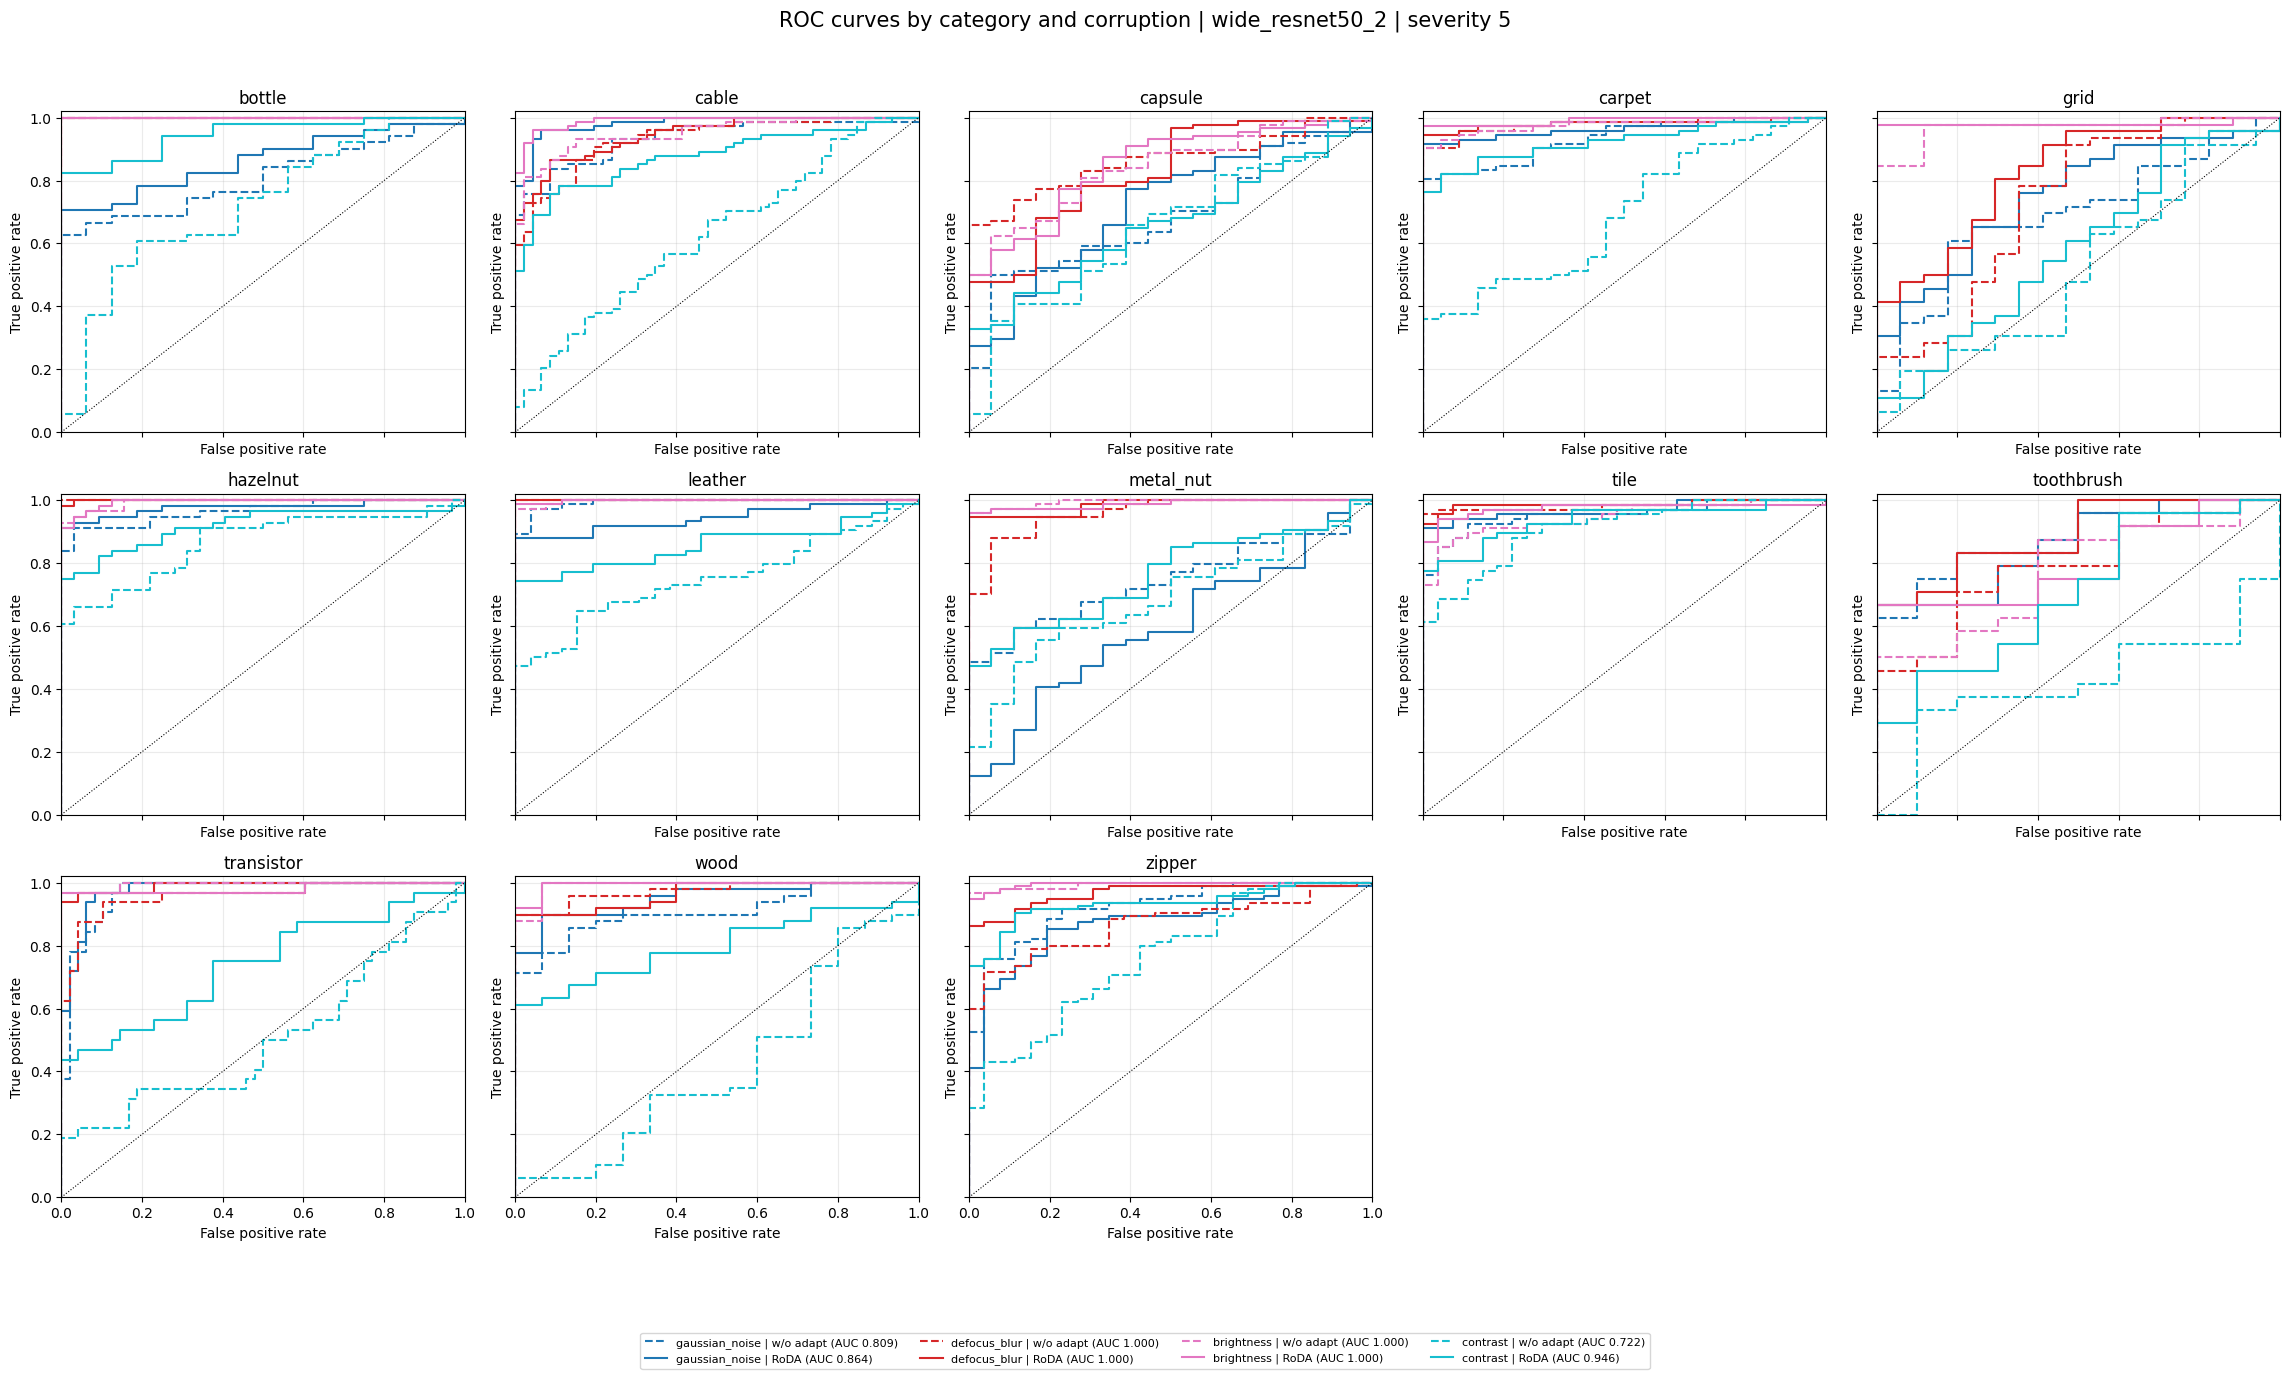

In [19]:
import numpy as np, torch, random, gc
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

SEED = 0
roc_store = {}
fig, axes = plt.subplots(3, 5, figsize=(23, 14), sharex=True, sharey=True)
axes = axes.ravel()
colors = plt.cm.tab10(np.linspace(0, 1, len(CFG.corruptions)))

for category_index, category in enumerate(CATEGORIES):
    with cfg_override(CFG, category=category, coreset_ratio=0.1):
        ax = axes[category_index]
        source_loader = DataLoader(
            SourceDataset(CFG, CFG.root, category),
            batch_size=CFG.batch_size,
            shuffle=False,
            num_workers=CFG.num_workers
        )
        category_bank = build_memory_bank(model, source_loader, CFG)
        del source_loader

        for color, corruption in zip(colors, CFG.corruptions):
            train_subset, test_subset = make_test_split(corruption, CFG)
            train_subset, test_subset = CachedDataset(train_subset), CachedDataset(test_subset)
            test_loader = make_loader(test_subset, CFG)
            scores_before, labels = score_images(model, test_loader, category_bank, CFG.device)

            torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)
            adapted_model, bn_params = make_adapt_model(CFG)
            adapt(adapted_model, bn_params, train_subset, category_bank, CFG)
            scores_after, _ = score_images(adapted_model, test_loader, category_bank, CFG.device)

            for scores, method, linestyle in [
                (scores_before, 'w/o adapt', '--'),
                (scores_after, 'RoDA', '-')
            ]:
                fpr, tpr, _ = roc_curve(labels, scores)
                auc = roc_auc_score(labels, scores)
                ax.plot(fpr, tpr, color=color, linestyle=linestyle, lw=1.5,
                        label=f'{corruption} | {method} (AUC {auc:.3f})')

            roc_store[f'{category}_{corruption}_before_scores'] = scores_before
            roc_store[f'{category}_{corruption}_after_scores'] = scores_after
            roc_store[f'{category}_{corruption}_labels'] = labels
            del train_subset, test_subset, test_loader, adapted_model, bn_params
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        ax.plot([0, 1], [0, 1], 'k:', lw=0.8)
        ax.set_title(category)
        ax.grid(alpha=0.25)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
        del category_bank
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

for ax in axes[len(CATEGORIES):]:
    ax.set_visible(False)
for ax in axes[:len(CATEGORIES)]:
    ax.set_xlabel('False positive rate')
    ax.set_ylabel('True positive rate')

handles, labels_for_legend = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_for_legend, loc='lower center', ncol=4, fontsize=8,
           bbox_to_anchor=(0.5, 0.005))
fig.suptitle(f'ROC curves by category and corruption | {CFG.backbone_name} | severity {CFG.severity}',
             fontsize=15)
fig.tight_layout(rect=[0, 0.09, 1, 0.96])
plt.show()
np.savez(f'roc_{CFG.backbone_name}_all_categories.npz', **roc_store)
CFG.category = 'bottle'


In [20]:
def get_threshold_at_fpr(normal_scores, target_fpr=0.05):
    normal_scores = np.asarray(normal_scores).reshape(-1)
    threshold = np.quantile(normal_scores, 1.0 - target_fpr)
    return threshold


def compute_recall(scores, labels, threshold):
    scores = np.asarray(scores).reshape(-1)
    labels = np.asarray(labels).reshape(-1)

    preds = (scores >= threshold).astype(int)
    tp = np.sum((preds == 1) & (labels == 1))
    fn = np.sum((preds == 0) & (labels == 1))

    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    return recall, tp, fn


def evaluate_recall(model, test_loader, memory_bank, CFG, normal_loader=None, target_fpr=0.075):
    test_scores, test_labels = score_images(
        model, test_loader, memory_bank, CFG.device
    )

    if normal_loader is not None:
        normal_scores, _ = score_images(
            model, normal_loader, memory_bank, CFG.device
        )
    else:
        normal_scores = test_scores[test_labels == 0]

    threshold = get_threshold_at_fpr(normal_scores, target_fpr)
    recall, tp, fn = compute_recall(test_scores, test_labels, threshold)

    return {
        "recall": recall,
        "threshold": threshold,
        "target_fpr": target_fpr,
        "true_positives": int(tp),
        "false_negatives": int(fn),
        "defective_images": int(tp + fn),
    }

In [21]:
def recall_before_roda(base_model, test_subset, memory_bank, CFG, target_fpr=0.075):

    return evaluate_recall(
        base_model,
        make_loader(test_subset, CFG),
        memory_bank, CFG,
        normal_loader=None,
        target_fpr=target_fpr
    )

def run_roda_seed_with_recall(target_tr, target_te, memory_bank, CFG, seed, target_fpr=0.075):

    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    res = evaluate_recall(
        model_a,
        make_loader(target_te, CFG),
        memory_bank,
        CFG,
        normal_loader=None,
        target_fpr=target_fpr
    )

    del model_a, bn_params
    torch.cuda.empty_cache()
    return res, history

In [22]:
import io
from contextlib import redirect_stdout

CATEGORIES = ["bottle", "cable", "capsule", "carpet", "grid", "hazelnut", "leather","metal_nut", "tile", "toothbrush", "transistor", "wood", "zipper"]

SEEDS = [0, 1, 2]
TARGET_FPR = 0.075
RECALL_EXCEL = "roda_recall_results.xlsx"
all_results = []

base_model = FeatureExtractor(CFG).to(CFG.device)

for category in CATEGORIES:
    with cfg_override(CFG, category=category, coreset_ratio=0.1):
        src = DataLoader(
            SourceDataset(CFG, CFG.root, category),
            batch_size=CFG.batch_size,
            shuffle=False,
            num_workers=CFG.num_workers
        )

        bank = build_memory_bank(base_model, src, CFG)

        for corruption in CFG.corruptions:
            tr, te = make_test_split(corruption, CFG)
            tr, te = CachedDataset(tr), CachedDataset(te)

            before = recall_before_roda(base_model, te, bank, CFG, TARGET_FPR)
            before.update(category=category, corruption=corruption, model="before_roda")
            all_results.append(before)
            recalls = []

            for seed in SEEDS:
                with redirect_stdout(io.StringIO()):
                    res, _ = run_roda_seed_with_recall(tr, te, bank, CFG, seed, TARGET_FPR)
                recalls.append(res["recall"])

            all_results.append(
                dict(category=category,
                     corruption=corruption,
                     model="after_roda",
                     recall=float(np.mean(recalls)),
                     recall_std=float(np.std(recalls)),
                     target_fpr=TARGET_FPR)
            )

            print(f"{category:12s} | {corruption:15s} | "
                  f"before {before['recall']:.4f} | after {np.mean(recalls):.4f}")

        del bank
        torch.cuda.empty_cache()
    pd.DataFrame(all_results).to_excel(RECALL_EXCEL, index=False)

recall_df = pd.DataFrame(all_results)
recall_pivot = recall_df.pivot_table(index=["category", "corruption"],
                                     columns="model", values="recall").reset_index()
recall_pivot["recall_improvement"] = recall_pivot["after_roda"] - recall_pivot["before_roda"]
print(recall_pivot.round(4))
recall_pivot.to_excel("RoDA_Recall_Before&After_results.xlsx", index=False)

print(CFG.category, CFG.coreset_ratio)

Source patches: 163856, memory bank size N_M: 16385
bottle       | gaussian_noise  | before 0.6863 | after 0.7059
bottle       | defocus_blur    | before 1.0000 | after 1.0000
bottle       | brightness      | before 1.0000 | after 1.0000
bottle       | contrast        | before 0.3922 | after 0.8235
Source patches: 175616, memory bank size N_M: 17561
cable        | gaussian_noise  | before 0.7703 | after 0.9595
cable        | defocus_blur    | before 0.7568 | after 0.8153
cable        | brightness      | before 0.8514 | after 0.9595
cable        | contrast        | before 0.2162 | after 0.7162
Source patches: 171696, memory bank size N_M: 17169
capsule      | gaussian_noise  | before 0.5000 | after 0.3561
capsule      | defocus_blur    | before 0.6932 | after 0.4773
capsule      | brightness      | before 0.6250 | after 0.6061
capsule      | contrast        | before 0.3636 | after 0.3750
Source patches: 219520, memory bank size N_M: 21952
carpet       | gaussian_noise  | before 0.8194 |

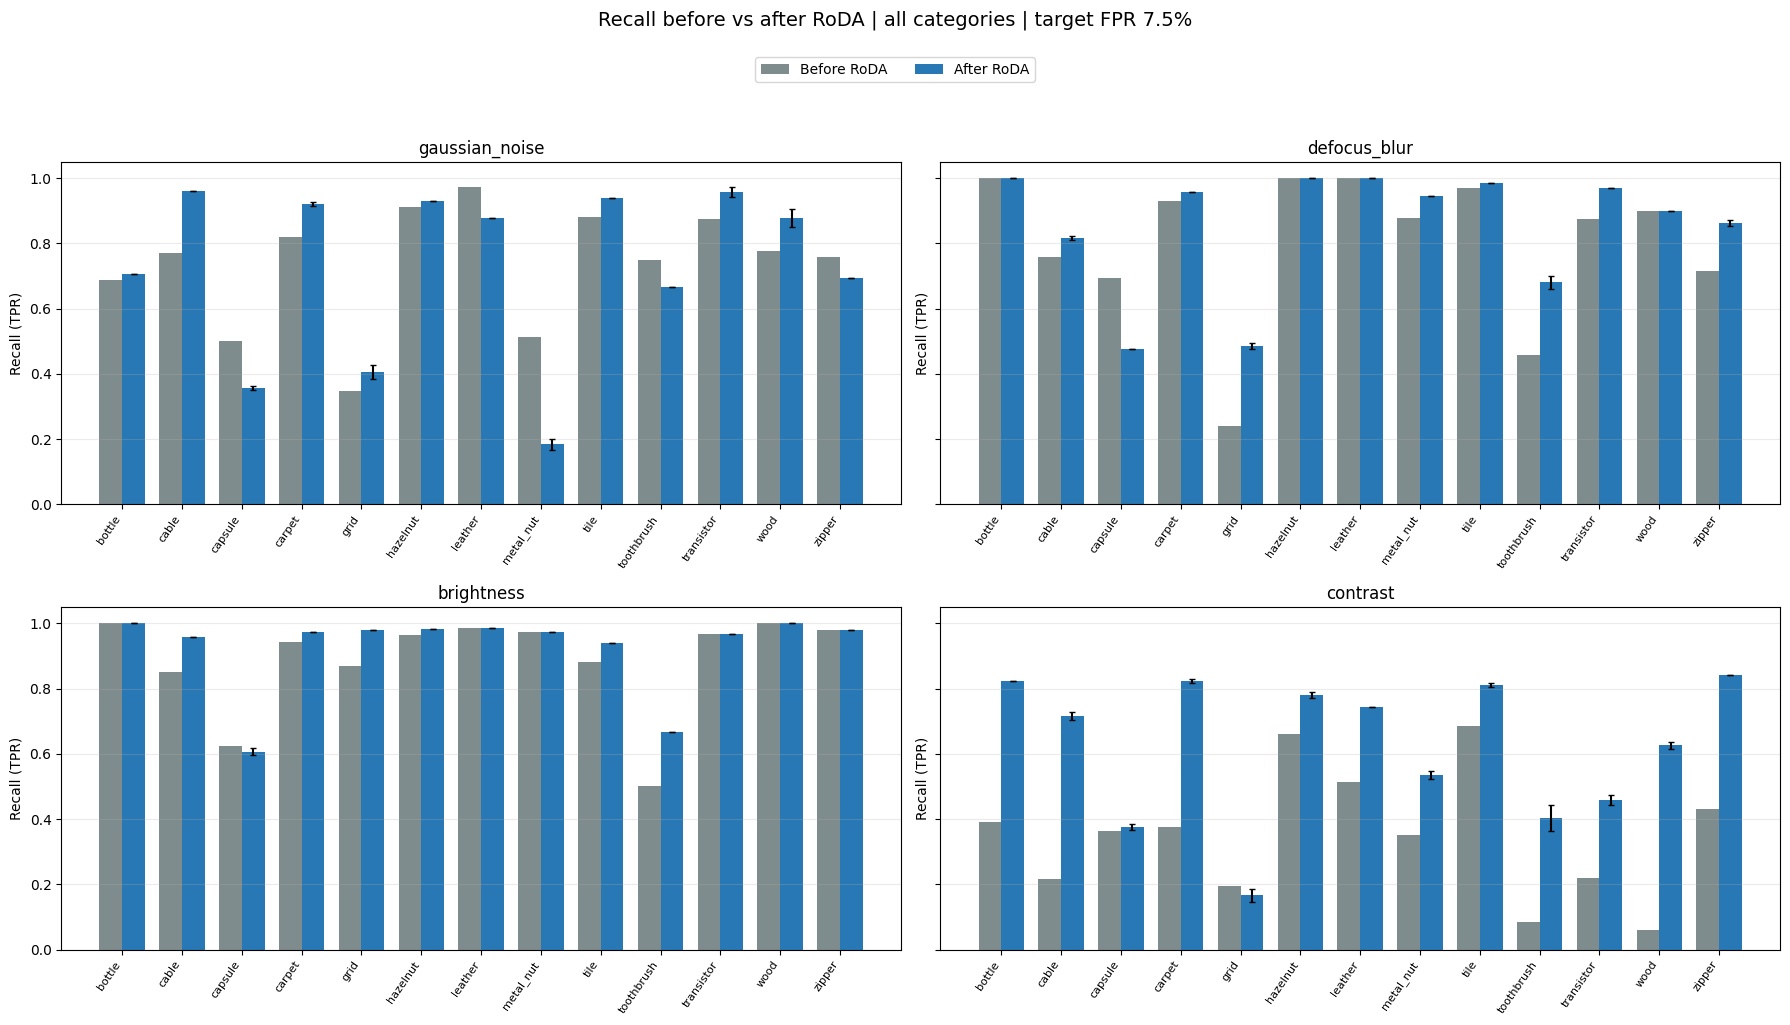

In [23]:
recall_plot_df = pd.DataFrame(all_results)
recall_summary = recall_plot_df.pivot_table(
    index=["category", "corruption"],
    columns="model",
    values="recall",
    aggfunc="mean"
).reset_index()

category_order = [c for c in CATEGORIES if c in set(recall_summary["category"])]
corruptions_to_plot = list(CFG.corruptions)
fig, axes = plt.subplots(2, 2, figsize=(18, 10), sharey=True)
axes = axes.ravel()
bar_width = 0.38

for ax, corruption in zip(axes, corruptions_to_plot):
    data = (recall_summary[recall_summary["corruption"] == corruption]
            .set_index("category")
            .reindex(category_order))
    x = np.arange(len(category_order))
    before_values = data["before_roda"].to_numpy(dtype=float)
    after_values = data["after_roda"].to_numpy(dtype=float)

    ax.bar(x - bar_width/2, before_values, bar_width,
           label="Before RoDA", color="#7f8c8d")
    after_std = (recall_plot_df[recall_plot_df["corruption"] == corruption]
                 .query("model == 'after_roda'")
                 .set_index("category")
                 .reindex(category_order)["recall_std"]
                 .fillna(0).to_numpy(dtype=float))
    ax.bar(x + bar_width/2, after_values, bar_width, yerr=after_std,
           capsize=2, label="After RoDA", color="#2878B5")

    ax.set_title(corruption)
    ax.set_xticks(x)
    ax.set_xticklabels(category_order, rotation=55, ha="right", fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Recall (TPR)")
    ax.grid(axis="y", alpha=0.25)

for ax in axes[len(corruptions_to_plot):]:
    ax.set_visible(False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.98))
fig.suptitle(f"Recall before vs after RoDA | all categories | target FPR {TARGET_FPR:.1%}",
             y=1.02, fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


## Defect Memory bank for classifying new defects

In [24]:
import torch.nn.functional as Fn

class DefectImages(Dataset):

    def __init__(self, root, category, CFG, corruption=None):
        self.CFG, self.corruption = CFG, corruption
        test_dir = os.path.join(root, category, "test")
        self.classes = [d for d in sorted(os.listdir(test_dir)) if d != "good"]
        self.items = []
        for ci, d in enumerate(self.classes):
            for p in sorted(glob.glob(os.path.join(test_dir, d, "*.*"))):
                self.items.append((p, ci))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        p, ci = self.items[idx]
        img = Image.open(p).convert("RGB")
        if self.corruption is not None:
            img = apply_corruption(img, self.corruption, self.CFG.severity, seed=self.CFG.seed + idx)
        return base_transform(img, self.CFG), ci


@torch.no_grad()
def defect_embeddings(model, loader, normal_bank, CFG, top_k=20, mode="residual", standardize=False):
    model.eval()
    mu, sd = normal_bank.mean(0), normal_bank.std(0) + 1e-6
    embs, labels = [], []

    for x, y in loader:
        feats = model(x.to(CFG.device))

        for i in range(feats.shape[0]):
            md, nn_idx = torch.cdist(feats[i], normal_bank).min(dim=1)
            idx = md.topk(top_k).indices
            v = feats[i][idx]
            if mode == "residual":
                v = v - normal_bank[nn_idx[idx]]
                if standardize: v = v / sd
            else:
                if standardize: v = (v - mu) / sd
            embs.append(Fn.normalize(v.mean(0), dim=0).cpu())
        labels.extend(y.tolist())
    return torch.stack(embs), np.array(labels)


class DefectBank:
    def __init__(self):
        self.embs = None
        self.cls = []
    def add(self, embs, class_id):
        embs = embs if embs.ndim == 2 else embs[None]
        self.embs = embs.clone() if self.embs is None else torch.cat([self.embs, embs])
        self.cls += [class_id] * embs.shape[0]
    def distances(self, q):
        d = 1 - q @ self.embs.T
        cls = torch.tensor(self.cls)
        ids = sorted(set(self.cls))
        per_class = torch.stack([d[:, cls == c].min(dim=1).values for c in ids], dim=1)
        return per_class, ids
    def classify(self, q, thr):
        per_class, ids = self.distances(q)
        mind, j = per_class.min(dim=1)
        pred = torch.tensor(ids)[j]
        pred[mind > thr] = -1
        return pred.numpy(), mind.numpy()


def closed_set_acc(embs, y, n_shot=3, seeds=range(5)):
    accs = []
    for s in seeds:
        rng = np.random.RandomState(s); bank = DefectBank(); test_idx = []
        for c in np.unique(y):
            idx = rng.permutation(np.where(y == c)[0])
            bank.add(embs[idx[:n_shot]], int(c)); test_idx += list(idx[n_shot:])
        pred, _ = bank.classify(embs[test_idx], thr=1e9)
        accs.append(np.mean(pred == y[test_idx]))
    return round(np.mean(accs), 3), round(np.std(accs), 3), "chance", round(1 / len(np.unique(y)), 3)


def run_grid(cat, model, CFG, n_shot=3, seeds=range(10)):
    with cfg_override(CFG, category=cat):
        src = DataLoader(SourceDataset(CFG, CFG.root, cat), batch_size=CFG.batch_size,
                         shuffle=False, num_workers=CFG.num_workers)
        bank = build_memory_bank(model, src, CFG)
        ds = DefectImages(CFG.root, cat, CFG)
        loader = DataLoader(ds, batch_size=CFG.batch_size, shuffle=False, num_workers=CFG.num_workers)
        rows = []
        for mode in ["raw", "residual"]:
            for std in [False, True]:
                for k in [5, 20, 50]:
                    e, yd = defect_embeddings(model, loader, bank, CFG, k, mode, std)
                    m, s, _, ch = closed_set_acc(e, yd, n_shot, seeds)
                    rows.append(dict(
                        category=cat,
                        mode=mode,
                        standardize=std,
                        top_k=k,
                        acc=m,
                        std=s,
                        chance=ch)
                    )

        del bank; torch.cuda.empty_cache()
    return pd.DataFrame(rows)


def calibrate_threshold(bank, cal_embs, cal_y, percentile=95):
    per_class, ids = bank.distances(cal_embs)
    col = {c: i for i, c in enumerate(ids)}
    true_d = np.array([per_class[i, col[int(c)]].item() for i, c in enumerate(cal_y)])
    return float(np.percentile(true_d, percentile))


def loco_eval(category, model, normal_bank, CFG, n_shot=3, percentile=95, top_k=20,seed=0, corruption=None, mode="residual", standardize=False):

    ds = DefectImages(CFG.root, category, CFG, corruption=corruption)
    loader = DataLoader(ds, batch_size=CFG.batch_size, shuffle=False, num_workers=CFG.num_workers)

    embs, y = defect_embeddings(model, loader, normal_bank, CFG, top_k, mode, standardize)
    rng, rows = np.random.RandomState(seed), []

    for u in range(len(ds.classes)):
        bank, cal_e, cal_y, tst_e, tst_y = DefectBank(), [], [], [], []

        for c in [k for k in range(len(ds.classes)) if k != u]:
            idx = rng.permutation(np.where(y == c)[0])
            if len(idx) < n_shot + 2:
                print(f"skip {ds.classes[c]}: only {len(idx)} images"); continue
            sup, rest = idx[:n_shot], idx[n_shot:]
            n_cal = max(1, len(rest) // 2)
            bank.add(embs[sup], c)
            cal_e.append(embs[rest[:n_cal]]); cal_y += [c] * n_cal
            tst_e.append(embs[rest[n_cal:]]); tst_y += [c] * len(rest[n_cal:])

        if bank.embs is None:
            continue


        cal_e, tst_e, tst_y = torch.cat(cal_e), torch.cat(tst_e), np.array(tst_y)
        thr = calibrate_threshold(bank, cal_e, np.array(cal_y), percentile)
        pred_k, d_k = bank.classify(tst_e, thr)
        pred_u, d_u = bank.classify(embs[y == u], thr)
        rows.append(dict(unknown=ds.classes[u], threshold=thr,
                         known_correct=np.mean(pred_k == tst_y),
                         known_wrong=np.mean((pred_k != -1) & (pred_k != tst_y)),
                         known_flagged_new=np.mean(pred_k == -1),
                         unknown_flagged_new=np.mean(pred_u == -1),
                         auroc_new_vs_known=roc_auc_score(
                             np.r_[np.zeros(len(d_k)), np.ones(len(d_u))], np.r_[d_k, d_u])))
    return pd.DataFrame(rows)

In [25]:
with cfg_override(CFG, root="./data", coreset_ratio=0.1):
    grid_old = pd.concat([
        run_grid(c, model, CFG)
        for c in ["carpet", "tile"]
    ], ignore_index=True)


with cfg_override(CFG, root="./New_defectdata", coreset_ratio=0.1):
    grid_new = pd.concat([
        run_grid(c, model, CFG)
        for c in ["pill", "screw"]
    ], ignore_index=True)

grid = pd.concat([grid_old, grid_new], ignore_index=True)

print(
    grid.sort_values(
        ["category", "acc"],
        ascending=[True, False]
    ).round(3).to_string(index=False)
)

print("Original root:", CFG.root)
print("Original category:", CFG.category)


Source patches: 219520, memory bank size N_M: 21952
Source patches: 180320, memory bank size N_M: 18032
Source patches: 209328, memory bank size N_M: 20932


KeyboardInterrupt: 

## Few shot learning for continual adaptation and training for new defects

In [ ]:
class FewShotHead(nn.Module):
    def __init__(self, in_dim=1024, rank=64, dropout=0.1):
        super().__init__()
        self.A = nn.Linear(in_dim, rank, bias=False)
        self.B = nn.Linear(rank, in_dim, bias=False)
        self.drop = nn.Dropout(dropout)
        nn.init.zeros_(self.B.weight)

    def forward(self, x):
        return Fn.normalize(x + self.B(self.drop(self.A(x))), dim=-1)


def embed(head, x):
    if head is None:
        return Fn.normalize(x, dim=-1)
    head.eval()
    return head(x)


def train_head(pools, n_shot=3, rank=64, episodes=300, n_way=5, n_query=5,
               lr=1e-3, wd=1e-2, scale=10.0, dropout=0.1, seed=0):
    keys = [k for k, v in pools.items() if len(v) >= n_shot + 1]
    if len(keys) < 2:
        raise ValueError("Need at least 2 classes with more than n_shot images to train the head.")
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    D = pools[keys[0]].shape[1]
    head = FewShotHead(D, rank, dropout)
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=wd)
    w = min(n_way, len(keys))
    losses = []
    head.train()
    for _ in range(episodes):
        chosen = torch.randperm(len(keys), generator=g)[:w].tolist()
        sup, qry, qy = [], [], []
        for j, ci in enumerate(chosen):
            x = pools[keys[ci]].float()
            idx = torch.randperm(len(x), generator=g)
            sup.append(x[idx[:n_shot]])
            q = x[idx[n_shot:n_shot + n_query]]
            qry.append(q)
            qy += [j] * len(q)
        protos = Fn.normalize(head(torch.cat(sup)).view(w, n_shot, -1).mean(1), dim=-1)
        logits = scale * head(torch.cat(qry)) @ protos.T
        loss = Fn.cross_entropy(logits, torch.tensor(qy))
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    head.eval()
    return head, losses


class FewShotDefectClassifier:
    def __init__(self, head=None):
        self.head, self.names, self.protos = head, [], None

    @torch.no_grad()
    def add_class(self, name, support_embs):
        p = Fn.normalize(embed(self.head, support_embs.float()).mean(0), dim=0)[None]
        if name in self.names:
            self.protos[self.names.index(name)] = p[0]
        else:
            self.names.append(name)
            self.protos = p if self.protos is None else torch.cat([self.protos, p])

    @torch.no_grad()
    def predict(self, embs, reject_below=None):
        sims = embed(self.head, embs.float()) @ self.protos.T
        best, j = sims.max(dim=1)
        out = [self.names[i] for i in j.tolist()]
        if reject_below is not None:
            out = [n if s >= reject_below else "unknown" for n, s in zip(out, best.tolist())]
        return out, best.numpy()


In [ ]:
def collect_category(cat, model, CFG, top_k=20, mode="residual", standardize=False,
                     corruption=None, coreset_ratio=0.1, root=None):
    data_root = CFG.root if root is None else root
    with cfg_override(CFG, category=cat, coreset_ratio=coreset_ratio):
        src = DataLoader(SourceDataset(CFG, data_root, cat), batch_size=CFG.batch_size,
                         shuffle=False, num_workers=CFG.num_workers)
        bank = build_memory_bank(model, src, CFG)
        ds = DefectImages(data_root, cat, CFG, corruption=corruption)
        loader = DataLoader(ds, batch_size=CFG.batch_size, shuffle=False, num_workers=CFG.num_workers)
        e, y = defect_embeddings(model, loader, bank, CFG, top_k, mode, standardize)
        del bank; torch.cuda.empty_cache()
    return {name: e[torch.as_tensor(y == i)] for i, name in enumerate(ds.classes)}


@torch.no_grad()
def eval_novel(head, base_eval, novel_x, n_shot=3, seed=0):
    rng = np.random.RandomState(seed)
    names = list(base_eval) + ["__new__"]
    protos, qry, qy = [], [], []
    for j, n in enumerate(names):
        x = (novel_x if n == "__new__" else base_eval[n]).float()
        idx = torch.as_tensor(rng.permutation(len(x)))
        protos.append(Fn.normalize(embed(head, x[idx[:n_shot]]).mean(0), dim=0))
        q = x[idx[n_shot:]]
        qry.append(q); qy += [j] * len(q)
    protos, qy = torch.stack(protos), np.array(qy)
    pred = (embed(head, torch.cat(qry)) @ protos.T).argmax(1).numpy()
    new = len(names) - 1
    return dict(novel_acc=float(np.mean(pred[qy == new] == new)),
                base_acc=float(np.mean(pred[qy != new] == qy[qy != new])),
                overall=float(np.mean(pred == qy)),
                chance=1 / len(names))


def loco_fewshot(cat_data, cat, n_shot=3, train_frac=0.5, seeds=range(5),
                 extra_pools=None, source="within", **head_kw):
    need = n_shot + 1
    rows = []
    for u in cat_data:
        novel_x = cat_data[u]
        if len(novel_x) < need:
            continue
        for sd in seeds:
            rng = np.random.RandomState(1000 + sd)
            base_eval, train_pools = {}, {}
            for n, x in cat_data.items():
                if n == u or len(x) < 2 * need:
                    continue
                idx = torch.as_tensor(rng.permutation(len(x)))
                k = int(len(x) * train_frac)
                train_pools[(cat, n)] = x[idx[:k]]
                base_eval[n] = x[idx[k:]]
            if not base_eval:
                continue
            pools = dict(extra_pools) if source == "cross" else train_pools
            head, _ = train_head(pools, n_shot=n_shot, seed=sd, **head_kw)
            for method, h in [("baseline (no head)", None), (f"head ({source})", head)]:
                r = eval_novel(h, base_eval, novel_x, n_shot, seed=sd)
                rows.append(dict(category=cat, unknown=u, seed=sd, method=method, **r))
    return pd.DataFrame(rows)


In [ ]:
FEWSHOT_CATS = ["pill", "screw", "carpet", "tile"]
N_SHOT = 3
HEAD_KW = dict(rank=64, episodes=300, n_way=5, n_query=5, lr=1e-3, wd=1e-2, scale=10.0, dropout=0.1)

NEW_DEFECT_ROOT = "./New_defectdata"
FEWSHOT_ROOTS = {
    "pill": NEW_DEFECT_ROOT,
    "screw": NEW_DEFECT_ROOT,
    "carpet": CFG.root,
    "tile": CFG.root,
}

data = {}
for c in FEWSHOT_CATS:
    t0 = time.time()
    data[c] = collect_category(c, model, CFG, root=FEWSHOT_ROOTS[c], corruption=None)
    print(f"{c} [{FEWSHOT_ROOTS[c]}]: {{ {', '.join(f'{k}: {len(v)}' for k, v in data[c].items())} }}  ({time.time()-t0:.0f}s)")

parts = []
for c in FEWSHOT_CATS:
    extra = {(o, n): v for o, d in data.items() if o != c for n, v in d.items()}
    parts.append(loco_fewshot(data[c], c, N_SHOT, extra_pools=None,  source="within", **HEAD_KW))
    parts.append(loco_fewshot(data[c], c, N_SHOT, extra_pools=extra, source="cross",  **HEAD_KW))
fs_df = pd.concat(parts, ignore_index=True).drop_duplicates()

print("\nPer category (mean over unknown defect types and seeds):")
print(fs_df.groupby(["category", "method"])[["novel_acc", "base_acc", "overall"]].mean().round(3))
print("\nAverage over categories:")
print(fs_df.groupby("method")[["novel_acc", "base_acc", "overall"]].mean().round(3))
fs_df.to_csv("fewshot_head_results.csv", index=False)


In [ ]:
NEW_DEFECT_ROOT = "./New_defectdata"
NEW_DEFECT_CATEGORIES = [
    name for name in ["pill", "screw"]
    if os.path.isdir(os.path.join(NEW_DEFECT_ROOT, name, "train", "good"))
    and os.path.isdir(os.path.join(NEW_DEFECT_ROOT, name, "test"))
]
N_SHOT_NEW = 3
NEW_DEFECT_SEEDS = range(5)
NEW_DEFECT_TOP_K = 20
MAX_NORMAL_BANK_IMAGES = 40
NEW_DEFECT_MODE = "residual"
NEW_DEFECT_STANDARDIZE = False
HEAD_KW_NEW = dict(rank=64, episodes=300, n_way=5, n_query=5,
                    lr=1e-3, wd=1e-2, scale=10.0, dropout=0.1)

if not NEW_DEFECT_CATEGORIES:
    raise FileNotFoundError(
        f"Expected folders such as {NEW_DEFECT_ROOT}/pill/test/<defect>"
    )

new_defect_frames = []
for category in NEW_DEFECT_CATEGORIES:
    print(f"\nNew_defectdata: {category} (no corruption), {N_SHOT_NEW}-shot leave-one-defect-out")
    with cfg_override(CFG, category=category, coreset_ratio=0.1):
        normal_source = SourceDataset(CFG, NEW_DEFECT_ROOT, category)
        rng_bank = np.random.RandomState(CFG.seed)
        chosen = rng_bank.permutation(len(normal_source.paths))[:MAX_NORMAL_BANK_IMAGES]
        normal_source.paths = [normal_source.paths[i] for i in chosen]
        source = DataLoader(
            normal_source, batch_size=CFG.batch_size, shuffle=False,
            num_workers=CFG.num_workers
        )
        normal_bank = build_memory_bank(model, source, CFG)

        defect_ds = DefectImages(NEW_DEFECT_ROOT, category, CFG, corruption=None)
        defect_loader = DataLoader(
            defect_ds, batch_size=CFG.batch_size, shuffle=False,
            num_workers=CFG.num_workers
        )
        embeddings, labels = defect_embeddings(
            model, defect_loader, normal_bank, CFG,
            top_k=NEW_DEFECT_TOP_K, mode=NEW_DEFECT_MODE,
            standardize=NEW_DEFECT_STANDARDIZE
        )
        category_data = {
            name: embeddings[torch.as_tensor(labels == class_id)]
            for class_id, name in enumerate(defect_ds.classes)
        }
        print("Defect classes and image counts:",
              {name: len(values) for name, values in category_data.items()})

        result = loco_fewshot(
            category_data, category, n_shot=N_SHOT_NEW, train_frac=0.5,
            seeds=NEW_DEFECT_SEEDS, source="within", **HEAD_KW_NEW
        )
        if result.empty:
            raise RuntimeError(f"No valid few-shot episodes were produced for {category}.")
        result["corruption"] = "none"
        result["n_shot"] = N_SHOT_NEW
        new_defect_frames.append(result)
        del normal_bank, source, normal_source, defect_loader, defect_ds
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

new_defect_results = pd.concat(new_defect_frames, ignore_index=True)
print("\nNew_defectdata results (mean across held-out defect classes and seeds):")
summary = new_defect_results.groupby(["category", "method"])[
    ["novel_acc", "base_acc", "overall", "chance"]
].mean().round(3)
print(summary.to_string())
new_defect_results.to_csv("New_defectdata_fewshot_results.csv", index=False)
print("Saved New_defectdata_fewshot_results.csv")